### Introduction

This tutorial shows how to use active learning to rapidly process a large dataset using a more computationally expensive method like docking, FEP, or 3D similarity calculations.  The code here is a scaled-down version of the code in our paper ["Optimizing active learning for free energy calculations"](https://www.sciencedirect.com/science/article/pii/S2667318522000204).  The code is fully functional.  I just removed a few of the options and benchmarks from our original work.  

### Setup

In [1]:
from operator import itemgetter

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.gaussian_process as gp
import useful_rdkit_utils as uru
from modAL.acquisition import BaseLearner
from modAL.models import BayesianOptimizer
from modAL.utils.data import modALinput
from modAL.acquisition import optimizer_PI
from rdkit import Chem
from sklearn.gaussian_process import GaussianProcessRegressor
from tqdm.auto import tqdm
from modAL.utils.selection import multi_argmax

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/Users/paulakramer/opt/anaconda3/envs/act_learn1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import utils
from pathlib import Path 
from rdkit.Chem import Descriptors
import random 
from collections import Counter 
import sys 
sys.path.insert(1, '/Users/paulakramer/Documents/PHD/KinFragLib/kinase_active_learning/notebooks/recombination')
from recombination import recombine_ligands
from recombination import cli 
import frag_modifications

from rdkit.Contrib.SA_Score import sascorer


### Reading the data

In [3]:
# Path to library folder
HERE = Path(_dh[-1])
PATH_TO_LIB = HERE / '..' / 'data' / 'fragment_library_custom_filtered'

In [4]:
fragment_library = utils.read_fragment_library(PATH_TO_LIB)
fragment_library.keys()

dict_keys(['AP', 'FP', 'SE', 'GA', 'B1', 'B2'])

In [5]:
fragment_library['AP'].sample(5).index

Index([102, 85, 19, 96, 60], dtype='int64')

In [6]:
fragment_library['AP'].iloc[0]

ROMol                <rdkit.Chem.rdchem.Mol object at 0x1487c50e0>
ROMol_dummy          <rdkit.Chem.rdchem.Mol object at 0x1487c5070>
ROMol_original       <rdkit.Chem.rdchem.Mol object at 0x1487c4e40>
kinase                                                       ACTR2
family                                                        STKR
group                                                          TKL
complex_pdb                                                   3q4t
ligand_pdb                                                     TAK
alt                                                              A
chain                                                            B
atom_subpockets          AP AP AP AP AP AP AP AP AP AP AP AP SE GA
atom_environments        16 16 16 16 16 16 16 16 16 16 16 16 na na
smiles                                               c1cnc2ccnn2c1
smiles_dummy                                     *c1cnc2c(*)cnn2c1
subpocket                                                     

### Defining an Oracle

As with the classification example, we'll define an oracle that looks up values from a dataframe.  In practice, the oracle would perform some more expensive calculation like docking, FEP, or shape overlap. 

In [7]:
# calculates SA score
class Oracle: 
    def __init__(self, df):
        self.df = df
        self.subpockets = ['AP', 'FP', 'GA', 'SE']

    def get_values(self, mols): 
        #return [Descriptors.MolLogP(Chem.MolFromSmiles(s)) for s in smi]
        return [sascorer.calculateScore(m) for m in mols]
    
    def sample_one_pocket(self, num, pocket):
        sample_df = self.df[pocket].sample(num)
        return sample_df.fp.values, self.get_values(sample_df.ROMol_dummy), sample_df.smiles
    
    def sample(self, num): 
        pocket_sample = random.choices(self.subpockets, k=num)
        counter = Counter(pocket_sample).most_common()
        sample_df = {}
        for count in counter: 
            sample_df[count[0]] = self.df[count[0]].sample(count[1])
            for ind in sample_df[count[0]].index: 
                sample_df[count[0]].loc[ind].ROMol_original.SetProp("Index", str(ind))
        lib_path = HERE / '..' / 'data' / 'temp_library'
        utils.delete_folder(lib_path)
        
        utils.save_fragment_library_to_sdfs(lib_path, pd.concat(sample_df))
        com_path = Path(HERE  / '..'/ "data" / "temp" / "recombined")
        cli.process(com_path, lib_path, 'AP', 3)
        # writes recombined ligands to combinatorial_library.sdf 
        recombine_ligands.process(self.df, com_path)
        mols = utils.read_sdf(com_path / "combinatorial_library.sdf")
        # remap mol props from temp_lib to kinfraglib 
        return list(map(uru.mol2numpy_fp, mols)), [Chem.MolToSmiles(m) for m in mols], mols

    def fragment_sampling(self, num, mols, vals): 
        zipped = zip(mols, vals)
        zipped = sorted(zipped, key=lambda x: x[1]) 
        ligands = []
        for mol, _ in zipped[:min(num, len(zipped))]: 
            frag_ids, bond_ids = utils.extract_meta(mol)
            res = frag_modifications.fragment_modification(frag_ids, bond_ids, self.df, self.subpockets)
            if res is not None: 
                if res[0] is not None: 
                    ligands.append(res[0])
        if None in ligands: 
            print("None in ligands")
        return list(map(uru.mol2numpy_fp, ligands)), [Chem.MolToSmiles(m) for m in ligands], ligands

In [8]:
#com_path = Path(HERE  / '..'/ "data" / "temp" / "recombined")
#recombine_ligands.process(fragment_library, com_path)

In [9]:
#from recombination import recombine_ligands 
#recombine_ligands.main()

#mols = utils.read_sdf(Path(HERE / '..' / "data" / "temp" / "recombined" / "combinatorial_library.sdf"))

frag_temp_library = utils.read_fragment_library(HERE / '..' / 'data' / 'temp_library')
frag_temp_library['AP'].smiles_dummy
#o_test = Oracle_lopg(frag_temp_library)
#res = o_test.fragment_sampling(5, mols[:10], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
#len(res[2])


0      *c1ccc2n[nH]c(C)c2c1
1       *CNC(=O)c1ccc(*)cc1
2             *c1cc(F)ccc1O
3             *Oc1cncc(*)n1
4     *c1c[nH]c2ccc(Cl)cc12
5             *c1cncc(Br)c1
6      *Nc1sc2c(c1C#N)CCCC2
7    *c1ccc2ncn(*)c(=O)c2c1
8           *c1cnc(N)c(*)n1
Name: smiles_dummy, dtype: object

In [10]:
fragment_library['AP'].iloc[41]

ROMol                <rdkit.Chem.rdchem.Mol object at 0x1487f60a0>
ROMol_dummy          <rdkit.Chem.rdchem.Mol object at 0x1487f5d90>
ROMol_original       <rdkit.Chem.rdchem.Mol object at 0x1487f5fc0>
kinase                                                        CK1d
family                                                         CK1
group                                                          CK1
complex_pdb                                                   4kbc
ligand_pdb                                                     1QJ
alt                                                              B
chain                                                            B
atom_subpockets       AP AP AP AP AP AP AP AP AP AP AP AP AP AP FP
atom_environments          16 16 16 16 16 16 16 16 16 8 8 8 3 3 na
smiles                                                  OCc1ccccn1
smiles_dummy                                         *c1ccnc(CO)c1
subpocket                                                     

In [11]:
#import frag_modifications
#import utils 
#from pathlib import Path 
#bond_ids = [('SE_10', 'AP_9'), ('AP_10', 'FP_12')]
#frag_ids = frozenset({'AP_0', 'FP_0', 'SE_4'})
#HERE = Path(_dh[-1])

#bond_ids1 = [('SE_8', 'AP_9'), ('AP_10', 'FP_9')]
#frag_ids1 = frozenset({'SE_2', 'AP_0', 'FP_2'})
#frag_temp_library = utils.read_fragment_library(HERE / 'data' / 'temp_library')
#ligand, new_frag_ids, new_bond_ids = frag_modifications.fragment_del(frag_ids1, bond_ids1, frag_temp_library)
#new_ligand, new_frag_ids, new_bond_ids = frag_modifications.fragment_add(new_frag_ids, new_bond_ids, frag_temp_library)


### Defining the Kernel Function for the Machine Learning Model

When we do active learning, we have to define a machine learning models that acts as a surrogate for the more expensive calculations.  In this case, we're going to use Gaussian Process Regression (GPR) to build our regression models.  To use GPR, we need to define a kernel function. Here we calculate a kernel based on the Tanimoto similarities of the molecules.

In [12]:
def calculate_similarity(a, b):
    # Tanimoto similarity a vs. b
    aa = np.sum(a, axis=1, keepdims=True)
    bb = np.sum(b, axis=1, keepdims=True)
    ab = np.matmul(a, b.T)
    return np.true_divide(ab, aa + bb.T - ab)


class TanimotoKernel(gp.kernels.NormalizedKernelMixin,
                     gp.kernels.StationaryKernelMixin, gp.kernels.Kernel):

    def __init__(self):
        pass

    def __call__(self, X, Y=None, eval_gradient=False):
        assert not eval_gradient
        if Y is None:
            Y = X
        return calculate_similarity(X, Y)

### Define Helper Functions for Active Learning

For the greedy search, we want to select the best scoring molecules, but we want to avoid selecting the same molecules multiple times. This function accepts a list of predictions and does the following.
- Sort by score
- Remove the molecules that were previously selected
- Return the top **n_to_choose**

In [13]:
def find_best_idx(predicted, used, num_to_choose):
    tmp_list = list(enumerate(predicted))
    tmp_list.sort(key=itemgetter(1), reverse=True)
    tmp_list = [x for x in tmp_list if x[0] not in used]
    tmp_list = [x[0] for x in tmp_list]
    return tmp_list[:num_to_choose]

Here are a couple of acquistion functions.  The first **greedy** simply selects the **n** top scoring molecules to be evaluated by the oracle.  The second **my_max_PI** maximizes the Probability of Improvement (PI) and uses uncertainty and the scores to balance exploration and exploitation.  The git repo associated with our paper ["Optimizing active learning for free energy calculations"](https://www.sciencedirect.com/science/article/pii/S2667318522000204) has examples of several other acquistion functions.  TLDR from our work, the acquistion function doesn't make a huge difference. 

In [14]:
def greedy(optimizer: BaseLearner, X: modALinput, n_instances=1, used=[]):
    res = optimizer.predict(X)
    best_idx = find_best_idx(res, used, n_instances)
    return best_idx, X[best_idx]

def my_max_PI(optimizer: BaseLearner, X: modALinput, tradeoff: float = 0,
           n_instances: int = 1, used = [], cycle = -1) -> np.ndarray:
    pi = optimizer_PI(optimizer, X, tradeoff=tradeoff)
    best_idx = find_best_idx(pi, used, n_instances)
    return best_idx, [X[i] for i in best_idx]

### Create an Oracle

Create an oracle that will return values. This example oracle just looks up a value in a table.  In practice, you'd put code here to do a more expensive calculation.  The notebook **active_shape_search.ipynb** has a complete implementation of an oracle. 

In [15]:
oracle = Oracle(fragment_library)

### Run Active Learning

This is the main active learning loop.

In [18]:
# number of molecules to select at each active learning cycle
n_instances = 30
# number of active learning cycles to run
n_cycles = 3

# define the acquistion function, to change to greedy just change the line below
query_strategy = my_max_PI
# select an initial random cycle
X_initial, sample_smi, sample_mols = oracle.sample(n_instances)
vals_init = oracle.get_values(sample_mols)
# instantiate the optimizer with an estimator, training data, and an acquistion function
optimizer = BayesianOptimizer(estimator=GaussianProcessRegressor(kernel=TanimotoKernel()),
                              X_training=np.stack(X_initial), y_training=vals_init,
                              query_strategy=query_strategy)
# initialize a list of scores
val_list = vals_init.copy()
# keep track of which molecules we've sampled
used = sample_smi
used_mols = sample_mols 
# the active learning loop
for i in tqdm(range(0, n_cycles)):
    # TODO: select fragments of chemical space -> fragment addition/deletion/exchange from used space 
    # fps, smi, mols = oracle_logp.sample(n_instances)     # currently: random selection 
    fps, sample_smi, sample_mols = oracle.fragment_sampling(n_instances, sample_mols, val_list)
    # ask the optimizer for the next set of molecules
    print(len(fps))
    # TODO: should used and fps/smi need to overlap? 
    used_idx = utils.check_used(sample_smi, used)
    query_ind, query_desc = optimizer.query(fps, n_instances=n_instances, used=used_idx)
    # get values from the oracle, in practice, this is where we would do the more expensive calculations
    vals = oracle.get_values([sample_mols[i] for i in query_ind])
    # add the returned values to val_list
    val_list += vals
    # keep track of the molecules we've used
    used += [sample_smi[i] for i in query_ind]
    used_mols += [sample_mols[i] for i in query_ind]
    # update the optimizer with the new values
    optimizer.teach(query_desc, vals)

Subpocket B1 not available.
Subpocket B2 not available.
Number of fragments:  30
Write 77 results to file 0
Number of resulting ligands:  77
Number of ligands including duplicates:  125
Overall number of fragments in queue:  22
Time:  12.408436298370361


[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running Normalizer
[12:59:56] Running Uncharger
[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running Normalizer
[12:59:56] Running Uncharger
[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running Normalizer
[12:59:56] Running Uncharger
[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running Normalizer
[12:59:56] Running Uncharger
[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running Normalizer
[12:59:56] Running Uncharger
[12:59:56] Initializing MetalDisconnector
[12:59:56] Running MetalDisconnector
[12:59:56] Initializing Normalizer
[12:59:56] Running No

Number of recombined ligands from all iterations: 77


 33%|███▎      | 1/3 [00:00<00:00,  2.55it/s]

30
30
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instruct

 67%|██████▋   | 2/3 [00:00<00:00,  2.40it/s]

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


100%|██████████| 3/3 [00:01<00:00,  2.36it/s]

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


### Analyze Active Learning Results

Let's see how many of the top 100 molecules we found.

In [ ]:
# sort the initial dataframe by score
ref_df = df.sort_values(value_column, ascending=False).head(100).copy()
# create a new dataframe with the selected molecules and sort by score
pick_df = df.iloc[used].sort_values(value_column, ascending=False).head(100).copy()
# merge the two dataframes to see how many molecules are in common
len(ref_df.merge(pick_df, on="ligand_id"))

Let's look at how the scores were distributed across the active learning cycles. First we need to put the data in a dataframe.

In [ ]:
res_list = []
for idx, v in enumerate(val_list):
    res_list += [(idx, x) for x in v]
res_df = pd.DataFrame(res_list, columns=["cycle", value_column])
# add row numbers for the selected molecules
res_df['mol_idx'] = used
# add the SMILES for the selected molecules 
res_df['SMILES'] = df.SMILES.values[used]
# reorder the columns in res_df
res_df = res_df[['SMILES','cycle','mol_idx','Activity']]
res_df

,SMILES,cycle,mol_idx,Activity
0,CC1(C)CC1C(=O)Nc1cc(NC(=O)c2ccccc2F)c(F)cn1,0,3588,-7.536533
1,Cc1cc(Nc2cc(NC(=O)c3c(C)cccc3C)ccn2)nc(Cl)n1,0,6359,-9.682870
2,CC(C)NC(=O)Nc1cc(NC(=O)c2c(Cl)cc(CO)cc2Cl)ccn1,0,3575,-11.636138
3,COc1cccc(Cl)c1C(=O)Nc1ccnc(NC(=O)CSC(F)F)c1,0,4232,-10.885722
4,COc1nccc(Nc2cc(NC(=O)c3cccc(N)c3Cl)ccn2)n1,0,6309,-8.979081
...,...,...,...,...
295,Nc1ccc(C(=O)Nc2cc(NC(=O)Oc3ccccc3)ncc2F)c(Cl)c1,5,7907,2.829416
296,Nc1nc(Nc2cc(NC(=O)c3c(F)ccc(F)c3Cl)ccn2)cc(C2C...,5,3814,3.930270
297,Cc1cc(Nc2cc(NC(=O)c3c(Cl)cccc3Cl)c(F)cn2)on1,5,6666,2.399566
298,CCS(=O)(=O)Nc1ccc(Nc2cc(NC(=O)c3c(F)cccc3Cl)cc...,5,5552,1.876460


Plot the scores of the molecules selected in each active learning round.  Remember that the first active learning cycle was randomly selected. 

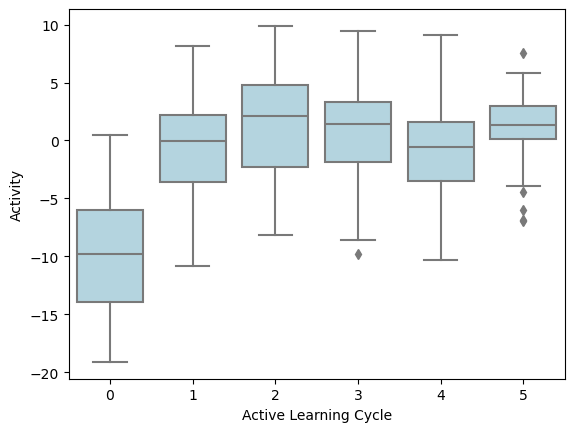

In [ ]:
ax = sns.boxplot(x="cycle", y=value_column, data=res_df,color="lightblue")
ax.set_xlabel("Active Learning Cycle");

Now let's plot the distributions for the top 100 molecules from the input data vs the top 100 found using active learning.

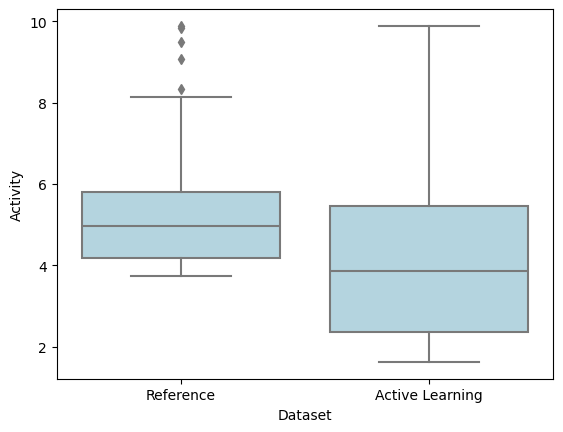

In [ ]:
# Get a dataframe with the top 100 reference molecules
ref_top_100 = ref_df.sort_values("Activity",ascending=False).head(100).copy()
ref_top_100['Dataset'] = 'Reference'
# Get a dataframe with top 100 molecules predicted by active learning
pred_top_100 = res_df.sort_values("Activity",ascending=False).head(100).copy()
pred_top_100['Dataset'] = 'Active Learning'
# Make a boxplot comparing the scores of the top 100 molecules
ax = sns.boxplot(x="Dataset", y="Activity", data=pd.concat([ref_top_100,pred_top_100]),color="lightblue");
ax.set_ylabel("Activity");

We can also compare the scores of the molecules selected by active learning with scores from randomly selected molecules. 

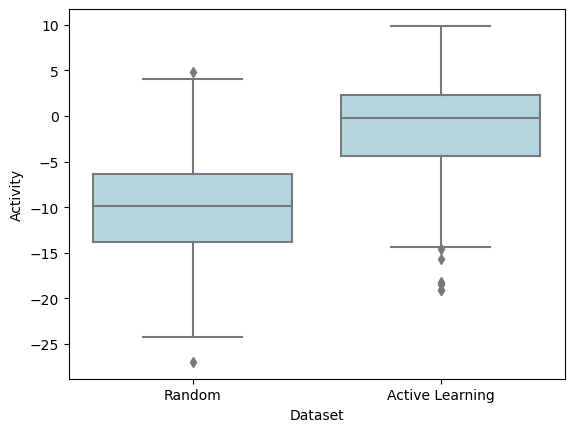

In [ ]:
# Take a random sample from the input data that is the same size as the dataframe with the selected molecules
random_df = df.sample(len(res_df)).copy()
random_df['Dataset'] = 'Random'
# Label the active learning data
res_df['Dataset'] = 'Active Learning'
ax = sns.boxplot(x="Dataset", y="Activity", data=pd.concat([random_df,res_df]),color="lightblue");
ax.set_ylabel("Activity");